In [1]:
#IMPORT LIBS
import geopandas as gpd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
from datetime import timedelta
import cartopy.util as cutil
#import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats
import pandas as pd


#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [2]:
#Define rectangular mask and plon, plat
# Define the resolution
lat_resolution = 2.5  # 2.5 degrees
lon_resolution = 2.5  # 2.5 degrees

# Define the global latitude and longitude ranges
latitudes = np.arange(60, 82.5, lat_resolution)  # From 0°N to 90°N
longitudes = np.arange(-70, -17.5, lon_resolution)  # From -180°E to 180°E

# Initialize a global mask with zeros
mask = np.zeros((len(latitudes), len(longitudes)))

# Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
lat_min, lat_max = 60, 80
lon_min, lon_max = -70, -20
plon = (lon_max + lon_min)/2
plat = (lat_max + lat_min)/2

# Assign 1 to grid points within the bounding box
for i, lat in enumerate(latitudes):
    if lat_min <= lat <= lat_max:
        for j, lon in enumerate(longitudes):
            if lon_min <= lon <= lon_max:
                mask[i, j] = 1

# Convert the mask to an xarray DataArray
mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
mask_bool = mask_xr.data == 1

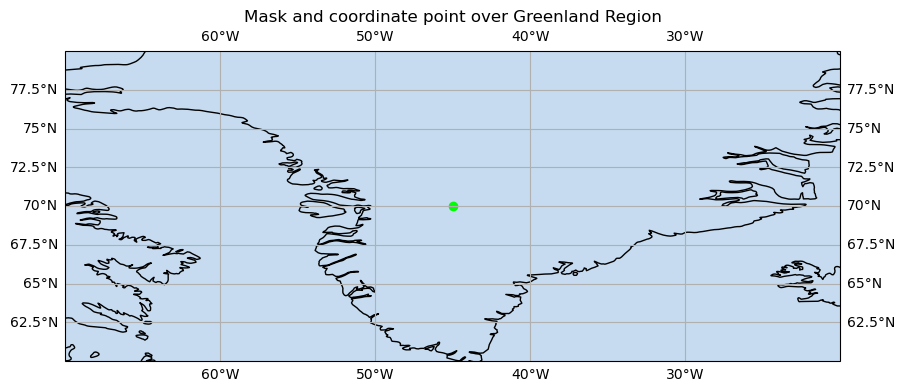

In [3]:
#LET's MAKE A PLOT TO VISUALIZE THE DOMAIN
# Plot the mask using Cartopy
plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-70, -20, 60, 80], crs=ccrs.PlateCarree())

# Plot the mask data
plt.contourf(mask_xr['lon'], mask_xr['lat'], mask_xr, cmap='Blues', transform=ccrs.PlateCarree())
plt.plot(plon,plat,marker='o',color='lime',transform=ccrs.PlateCarree())

# Add coastlines and gridlines
ax.add_feature(cfeature.COASTLINE)
ax.gridlines(draw_labels=True)

# Add title
plt.title('Mask and coordinate point over Greenland Region')

# Show the plot
plt.show()

In [4]:
'''
Importing the dictionaries
'''
import os
# Path to the dataset directory
dictionaries_path = "/disco/share/jm1427/greenblock/historical/DAV"

# List all files, excluding those with 'unfilt' in the name
dic_file_list = [
    f for f in os.listdir(dictionaries_path) 
    if os.path.isfile(os.path.join(dictionaries_path, f)) and 'unfilt' not in f
]

dic_file_list = sorted(dic_file_list)

In [5]:
%cd /disco/share/jm1427/greenblock/historical/DAV
#!ls
dics = []
for string in dic_file_list:
    dics.append(np.load(string,allow_pickle=True))

/disco/share/jm1427/greenblock/historical/DAV


In [6]:
print(len(dics))

108


In [7]:
'''
Importing the datasets
'''
import os
# Path to the dataset directory
dataset_path = "/disco/share/jm1427/greenblock/BI/historical"

# List all files, excluding those with 'unfilt' in the name
dataset_file_list = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'unfilt' not in f and 'GHA' not in f
]

dataset_file_list = sorted(dataset_file_list)

In [8]:
len(dataset_file_list)

108

In [9]:
%cd /disco/share/jm1427/greenblock/BI/historical
#!ls
datasets = []
for string in dataset_file_list:
    datasets.append(xr.open_dataset(string))

/disco/share/jm1427/greenblock/BI/historical


In [10]:
len(datasets)

108

# FIGURE 1

## Frequency

In [12]:
def running_mean(data,window):
    new_data = []
    for i in range(len(data)-window):
        new_data.append(np.sum(data[i:i+window])/window)
    #print(len(new_data))
    return new_data

In [31]:
months = ['06','07','08']
count_DAV = np.zeros((3))
count_m = 0
freq_per_month = [[[],[],[]]]
mask_size = np.sum(mask_xr,axis=(0,1))
tmp = '06'
for i,dic in tqdm(enumerate(dics)):
    print(dic_file_list[i])
    print(dataset_file_list[i])
    print(len(datasets[i]['time']))
    counts = np.zeros((3))
    DAV_filt = datasets[i]['DAV_tracked']
    for t in range(len(datasets[i]['time'])):
        month = str(datasets[i]['time'][t].values)[5:7]
        DAV_gr = DAV_filt.values[t,mask_bool]
        if month in months:
            #method3
            count_m += 1
            threshold = 0.2
            for l in np.unique(DAV_gr):
                if l != 0 and np.sum(DAV_gr==l) > threshold*mask_size/2:
                    count_DAV[0] += 1
                    #print('OK')
                if l != 0 and np.mean(dics[i][l]['track'][1])>plon and np.sum(DAV_gr==l) > threshold*mask_size/2:
                    count_DAV[1] += 1
                    #print('OK')
                if l != 0 and np.mean(dics[i][l]['track'][1])<=plon and np.sum(DAV_gr==l) > threshold*mask_size/2:
                    count_DAV[2] += 1
                    #print('OK')


            if month != tmp:
                tmp = month
                freq_per_month[i][0].append(count_DAV[0]*100/count_m)
                freq_per_month[i][1].append(count_DAV[1]*100/count_m)
                freq_per_month[i][2].append(count_DAV[2]*100/count_m)   
                count_DAV = np.zeros((3))
                count_m = 0
    freq_per_month.append([[],[],[]])

0it [00:00, ?it/s]

MPI-ESM1-2-LR_r2i1p1f1_northem_2.5x2.5_zg_DAV_tracked_daily_DIC_paper.npy
MPI-ESM1-2-LR_r2i1p1f1_northem_2.5x2.5_zg_DAV_tracked_daily_summer_60-80N_70-20W.nc
5980


1it [00:02,  2.62s/it]

MPI-ESM1-2-LR_r2i1p1f1_northem_2.5x2.5_zg_DAV_tracked_daily_DIC_paper.npy
MPI-ESM1-2-LR_r2i1p1f1_northem_2.5x2.5_zg_DAV_tracked_daily_summer_60-80N_70-20W.nc
5980


2it [00:05,  2.62s/it]

MPI-ESM1-2-LR_r2i1p1f1_northem_2.5x2.5_zg_DAV_tracked_daily_DIC_paper.npy
MPI-ESM1-2-LR_r2i1p1f1_northem_2.5x2.5_zg_DAV_tracked_daily_summer_60-80N_70-20W.nc
5980


3it [00:07,  2.65s/it]


MPI-ESM1-2-LR_r2i1p1f1_northem_2.5x2.5_zg_DAV_tracked_daily_DIC_paper.npy
MPI-ESM1-2-LR_r2i1p1f1_northem_2.5x2.5_zg_DAV_tracked_daily_summer_60-80N_70-20W.nc
15180


KeyboardInterrupt: 

In [20]:
data_arrays_model_freq = []

for i,model_freq in enumerate(freq_per_month[:-1]):
    # Define a time range
    date_range = pd.date_range(str(datasets[i]['time'][0].values),periods=len(model_freq[0])*12/3-6, freq="ME")
    # Define the months to keep
    selected_months = [6,7,8]
    # Filter the date range based on the months
    filtered_dates = date_range[date_range.month.isin(selected_months)]

    # Create the DataArray
    data_array = xr.DataArray(
    data=np.array(model_freq[0]),  # Optional: Leave as None or provide some data
    dims=["time"],  # Define the dimension
    coords={"time": filtered_dates},  # Define the coordinate
    name="example_array",  # Optional: Name of the DataArray
    attrs={"description": "A DataArray with only a time dimension"}  # Optional: Attributes
    )

    data_arrays_model_freq.append(data_array)

/tmp/ipykernel_178463/4154852876.py:5: FutureWarning: Non-integer 'periods' in pd.date_range, pd.timedelta_range, pd.period_range, and pd.interval_range are deprecated and will raise in a future version.
  date_range = pd.date_range(str(datasets[i]['time'][0].values),periods=len(model_freq[0])*12/3-6, freq="ME")


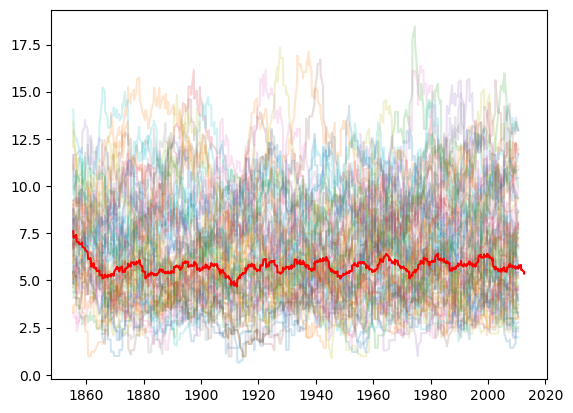

In [21]:
for i,model_freq in enumerate(data_arrays_model_freq):
    time = model_freq['time']
    rolling_mean = model_freq.rolling(time=30, center=True).mean()
    plt.plot(time,rolling_mean,alpha=0.2)

ensemble_model_freq = xr.concat(data_arrays_model_freq,dim='ens')

ens_mean = ensemble_model_freq.mean('ens')
ens_mean_roll_mean = ens_mean.rolling(time=30, center=True).mean()
time = ens_mean['time']
plt.plot(time,ens_mean_roll_mean,color='r')

In [26]:
data_arrays_model_freq = []

for i,model_freq in enumerate(freq_per_month[:-1]):
    # Define a time range
    date_range = pd.date_range(str(datasets[i]['time'][1].values),periods=len(model_freq[0])*12/3-6, freq="ME")
    # Define the months to keep
    selected_months = [6,7,8]
    # Filter the date range based on the months
    filtered_dates = date_range[date_range.month.isin(selected_months)]

    # Create the DataArray
    data_array = xr.DataArray(
    data=np.array(model_freq[1]),  # Optional: Leave as None or provide some data
    dims=["time"],  # Define the dimension
    coords={"time": filtered_dates},  # Define the coordinate
    name="example_array",  # Optional: Name of the DataArray
    attrs={"description": "A DataArray with only a time dimension"}  # Optional: Attributes
    )

    data_arrays_model_freq.append(data_array)

/tmp/ipykernel_178463/1279911126.py:5: FutureWarning: Non-integer 'periods' in pd.date_range, pd.timedelta_range, pd.period_range, and pd.interval_range are deprecated and will raise in a future version.
  date_range = pd.date_range(str(datasets[i]['time'][1].values),periods=len(model_freq[0])*12/3-6, freq="ME")


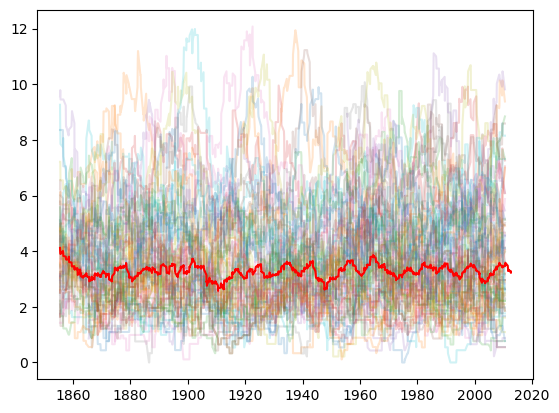

In [27]:
for i,model_freq in enumerate(data_arrays_model_freq):
    time = model_freq['time']
    rolling_mean = model_freq.rolling(time=30, center=True).mean()
    plt.plot(time,rolling_mean,alpha=0.2)

ensemble_model_freq = xr.concat(data_arrays_model_freq,dim='ens')

ens_mean = ensemble_model_freq.mean('ens')
ens_mean_roll_mean = ens_mean.rolling(time=30, center=True).mean()
time = ens_mean['time']
plt.plot(time,ens_mean_roll_mean,color='r')

In [28]:
data_arrays_model_freq = []

for i,model_freq in enumerate(freq_per_month[:-1]):
    # Define a time range
    date_range = pd.date_range(str(datasets[i]['time'][2].values),periods=len(model_freq[0])*12/3-6, freq="ME")
    # Define the months to keep
    selected_months = [6,7,8]
    # Filter the date range based on the months
    filtered_dates = date_range[date_range.month.isin(selected_months)]

    # Create the DataArray
    data_array = xr.DataArray(
    data=np.array(model_freq[2]),  # Optional: Leave as None or provide some data
    dims=["time"],  # Define the dimension
    coords={"time": filtered_dates},  # Define the coordinate
    name="example_array",  # Optional: Name of the DataArray
    attrs={"description": "A DataArray with only a time dimension"}  # Optional: Attributes
    )

    data_arrays_model_freq.append(data_array)

/tmp/ipykernel_178463/741235180.py:5: FutureWarning: Non-integer 'periods' in pd.date_range, pd.timedelta_range, pd.period_range, and pd.interval_range are deprecated and will raise in a future version.
  date_range = pd.date_range(str(datasets[i]['time'][2].values),periods=len(model_freq[0])*12/3-6, freq="ME")


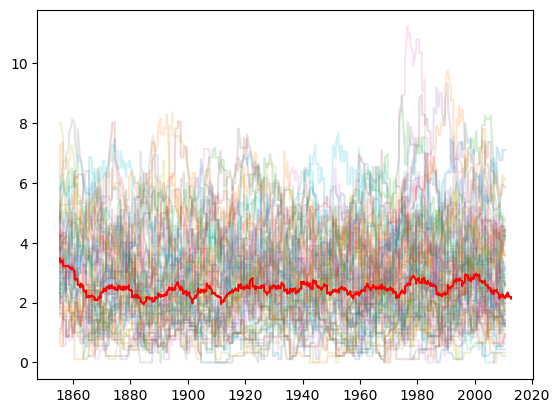

In [29]:
for i,model_freq in enumerate(data_arrays_model_freq):
    time = model_freq['time']
    rolling_mean = model_freq.rolling(time=30, center=True).mean()
    plt.plot(time,rolling_mean,alpha=0.2)

ensemble_model_freq = xr.concat(data_arrays_model_freq,dim='ens')

ens_mean = ensemble_model_freq.mean('ens')
ens_mean_roll_mean = ens_mean.rolling(time=30, center=True).mean()
time = ens_mean['time']
plt.plot(time,ens_mean_roll_mean,color='r')